Load Eurostat TSV Datasets
This cell automatically detects the project root directory, locates all raw Eurostat TSV files inside the data/raw/data_eurostat folder, loads them into Pandas DataFrames, and displays a quick preview (row/column counts and first 5 rows) for each dataset.

In [3]:
from pathlib import Path
from IPython.display import display
import pandas as pd

project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw" / "data_eurostat"
tsv_files = sorted(data_dir.glob("*.tsv"))

if not tsv_files:
    raise FileNotFoundError(f"No TSV files found in {data_dir}")

eurostat_data = {}
for tsv_path in tsv_files:
    frame = pd.read_csv(tsv_path, sep="\t", low_memory=False)
    eurostat_data[tsv_path.stem] = frame

    print(f"{tsv_path.name}: {frame.shape[0]:,} rows, {frame.shape[1]} columns")
    display(frame.head())

hsw_mi01.tsv: 10,080 rows, 18 columns


,"freq,unit,age,sex,severity,nace_r2,geo\TIME_PERIOD",2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,"A,NR,TOTAL,F,D_GE4,A_C-N,AT",10064,9386,10351,9751,9568,9056,9226,8915,9195,9089,9412,9280,7336 b,7876,8225,8658,8804
1,"A,NR,TOTAL,F,D_GE4,A_C-N,BE",10356,9118,10288,9985,9093,8792,8737 b,8955,9475,9597,9878,9525,7563 b,8364,8487,8477,8227
2,"A,NR,TOTAL,F,D_GE4,A_C-N,BG",594,448,448,399,415,388,434,428,464,482,476,494,388 b,400,475,500,526
3,"A,NR,TOTAL,F,D_GE4,A_C-N,CH",10304,10640,10787,11641,11754,12009,11648,11989,12170,12424,12678,13182,11581 b,12501,13445,14333,14367
4,"A,NR,TOTAL,F,D_GE4,A_C-N,CY",401,399,419,384,384,366,375,347,434,469,458,535,268 b,268,273,281,299


hsw_n2_02.tsv: 7,840 rows, 18 columns


,"freq,unit,nace_r2,geo\TIME_PERIOD",2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,"A,NR,A,AT",76,67,86,53,50,58,69,63,54,27,58,38,46 b,45,38,64,53
1,"A,NR,A,BE",3,2,1,4,0,1,0 b,4,0,0,1,1,1 b,3,2,1,0
2,"A,NR,A,BG",5,1,8,6,11,3,8,8,2,7,11,5,9 b,4,4,8,4
3,"A,NR,A,CH",4,8,4,3,7,1,5,3,4,1,4,4,3 b,2,3,6,4
4,"A,NR,A,CY",0,1,3,1,1,1,0,0,2,0,0,0,0 b,1,1,0,1


Download and Load the Non-Fatal Accidents Dataset (hsw_n2_01)
This cell checks if a specific Eurostat dataset (hsw_n2_01.tsv) already exists locally. If it is missing, it automatically downloads the file from the Eurostat API, validates the format, saves it to your data directory, and loads it into the eurostat_data dictionary.    

In [5]:
import requests

nonfatal_path = data_dir / "hsw_n2_01.tsv"
nonfatal_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/"
    "hsw_n2_01?format=TSV&compressed=false"
)

if not nonfatal_path.exists():
    response = requests.get(
        nonfatal_url,
        headers={"User-Agent": "Mozilla/5.0 (compatible; Eurostat-data-analysis/1.0)"},
        timeout=120,
    )
    response.raise_for_status()
    if b"\t" not in response.content[:2000]:
        raise ValueError("Eurostat response does not look like a TSV file")
    nonfatal_path.write_bytes(response.content)
    print(f"Downloaded {nonfatal_path.name} to {data_dir}")
else:
    print(f"Using existing file: {nonfatal_path}")

nonfatal_frame = pd.read_csv(nonfatal_path, sep="\t", low_memory=False)
eurostat_data["hsw_n2_01"] = nonfatal_frame
print(f"Non-fatal accidents: {len(nonfatal_frame):,} rows, {len(nonfatal_frame.columns)} columns")

Downloaded hsw_n2_01.tsv to c:\Users\micha\OneDrive\Desktop\magda\VSC\Project_15\data\raw\data_eurostat
Non-fatal accidents: 31,360 rows, 18 columns


Process, Clean, and Analyze Eurostat Accident Datasets
This cell transforms the wide-format Eurostat data into long-format tidy data, determines the latest common reporting year, maps country and industry codes to human-readable names, and generates six analytical tables covering country rankings, industry rates, historical trends, gender comparisons, accident counts by sector, and a country-by-industry heatmap matrix.

In [ ]:
import re


def eurostat_to_long(frame):
    dimension_column = frame.columns[0]
    dimension_names = [
        name.split("\\")[0] for name in dimension_column.split(",")
    ]
    dimensions = frame[dimension_column].astype("string").str.split(",", expand=True)
    if dimensions.shape[1] != len(dimension_names):
        raise ValueError(f"Unexpected dimension layout in {dimension_column}")
    dimensions.columns = dimension_names

    year_columns = frame.drop(columns=[dimension_column]).copy()
    year_columns.columns = [str(column).strip() for column in year_columns.columns]
    wide = pd.concat([dimensions, year_columns], axis=1)
    long = wide.melt(
        id_vars=dimension_names,
        var_name="year",
        value_name="value_raw",
    )
    long["year"] = long["year"].astype("string").str.strip()
    number_text = long["value_raw"].astype("string").str.extract(
        r"^\s*(-?\d+(?:\.\d+)?)",
        expand=False,
    )
    long["value"] = pd.to_numeric(number_text, errors="coerce")
    return long


fatal_counts = eurostat_to_long(eurostat_data["hsw_n2_02"])
fatality_rates = eurostat_to_long(eurostat_data["hsw_mi01"])
nonfatal_counts = eurostat_to_long(eurostat_data["hsw_n2_01"])

years_by_dataset = [
    set(frame["year"].dropna().astype(str))
    for frame in [fatal_counts, fatality_rates, nonfatal_counts]
]
common_years = set.intersection(*years_by_dataset)
analysis_year = str(max(int(year) for year in common_years if year.isdigit()))
print(f"Latest common year used for comparisons: {analysis_year}")

country_names = {
    "AT": "Austria", "BE": "Belgium", "BG": "Bulgaria", "CH": "Switzerland",
    "CY": "Cyprus", "CZ": "Czechia", "DE": "Germany", "DK": "Denmark",
    "EE": "Estonia", "EL": "Greece", "ES": "Spain", "FI": "Finland",
    "FR": "France", "HR": "Croatia", "HU": "Hungary", "IE": "Ireland",
    "IS": "Iceland", "IT": "Italy", "LT": "Lithuania", "LU": "Luxembourg",
    "LV": "Latvia", "MT": "Malta", "NL": "Netherlands", "NO": "Norway",
    "PL": "Poland", "PT": "Portugal", "RO": "Romania", "SE": "Sweden",
    "SI": "Slovenia", "SK": "Slovakia", "UK": "United Kingdom",
}
industry_names = {
    "A": "Agriculture, forestry and fishing",
    "B": "Mining and quarrying",
    "C": "Manufacturing",
    "D": "Electricity, gas and steam",
    "E": "Water supply and waste management",
    "F": "Construction",
    "G": "Wholesale and retail trade",
    "H": "Transport and storage",
    "I": "Accommodation and food services",
    "J": "Information and communication",
    "K": "Financial and insurance activities",
    "L": "Real estate activities",
    "M": "Professional and technical activities",
    "N": "Administrative and support services",
    "O": "Public administration and defence",
    "P": "Education",
    "Q": "Human health and social work",
    "R": "Arts and entertainment",
    "S": "Other service activities",
}
industry_codes = list(industry_names)

# 1. Country ranking by standardized fatality rate per 100,000 workers.
country_rates_table = fatality_rates.loc[
    fatality_rates["unit"].eq("RT_SINC")
    & fatality_rates["age"].eq("TOTAL")
    & fatality_rates["sex"].eq("T")
    & fatality_rates["severity"].eq("FAT")
    & fatality_rates["nace_r2"].eq("A_C-N")
    & fatality_rates["year"].eq(analysis_year)
    & fatality_rates["geo"].isin(country_names)
    & fatality_rates["value"].notna(),
    ["geo", "value"],
].rename(columns={"geo": "Country", "value": "Fatalities per 100,000 workers"})
country_rates_table["Country"] = country_rates_table["Country"].map(country_names)
country_rates_table = country_rates_table.sort_values(
    "Fatalities per 100,000 workers", ascending=False
).head(20).reset_index(drop=True)

# Use broad NACE sections so industries are comparable rather than mixing sections and sub-sectors.
broad_industry = lambda frame: frame["nace_r2"].astype("string").isin(industry_codes)

# 2. EU fatality incidence rate by broad industry.
industry_rate_table = fatal_counts.loc[
    fatal_counts["unit"].eq("RT_INC")
    & fatal_counts["geo"].eq("EU27_2020")
    & fatal_counts["year"].eq(analysis_year)
    & broad_industry(fatal_counts)
    & fatal_counts["value"].notna(),
    ["nace_r2", "value"],
].rename(columns={"nace_r2": "Industry code", "value": "Fatal accidents per 100,000 workers"})
industry_rate_table["Industry"] = industry_rate_table["Industry code"].map(industry_names)
industry_rate_table = industry_rate_table[
    ["Industry", "Industry code", "Fatal accidents per 100,000 workers"]
].sort_values("Fatal accidents per 100,000 workers", ascending=False).reset_index(drop=True)

# 3. EU-wide standardized fatality-rate trend.
trend_table = fatality_rates.loc[
    fatality_rates["unit"].eq("RT_SINC")
    & fatality_rates["age"].eq("TOTAL")
    & fatality_rates["sex"].eq("T")
    & fatality_rates["severity"].eq("FAT")
    & fatality_rates["nace_r2"].eq("A_C-N")
    & fatality_rates["geo"].eq("EU27_2020")
    & fatality_rates["value"].notna(),
    ["year", "value"],
].rename(columns={"year": "Year", "value": "Fatalities per 100,000 workers"})
trend_table["Year"] = trend_table["Year"].astype(int)
trend_table = trend_table.sort_values("Year").reset_index(drop=True)

if len(trend_table) >= 2:
    first_rate = trend_table.iloc[0]["Fatalities per 100,000 workers"]
    latest_rate = trend_table.iloc[-1]["Fatalities per 100,000 workers"]
    trend_change_pct = (latest_rate - first_rate) / first_rate * 100
else:
    trend_change_pct = float("nan")

# 4. Compare male and female standardized fatality rates in the EU.
sex_rates = fatality_rates.loc[
    fatality_rates["unit"].eq("RT_SINC")
    & fatality_rates["age"].eq("TOTAL")
    & fatality_rates["sex"].isin(["F", "M"])
    & fatality_rates["severity"].eq("FAT")
    & fatality_rates["nace_r2"].eq("A_C-N")
    & fatality_rates["geo"].eq("EU27_2020")
    & fatality_rates["year"].eq(analysis_year),
    ["sex", "value"],
]
sex_rate_values = sex_rates.set_index("sex")["value"].to_dict()
sex_comparison_table = pd.DataFrame([{
    "Year": int(analysis_year),
    "Female rate per 100,000 workers": sex_rate_values.get("F"),
    "Male rate per 100,000 workers": sex_rate_values.get("M"),
    "Male-to-female rate ratio": (
        sex_rate_values["M"] / sex_rate_values["F"]
        if sex_rate_values.get("F") not in (None, 0)
        else float("nan")
    ),
}])

# 5. Fatal and non-fatal counts plus their share of all recorded accidents by industry.
fatal_by_industry = fatal_counts.loc[
    fatal_counts["unit"].eq("NR")
    & fatal_counts["geo"].eq("EU27_2020")
    & fatal_counts["year"].eq(analysis_year)
    & broad_industry(fatal_counts),
    ["nace_r2", "value"],
].rename(columns={"value": "Fatal accidents"})
nonfatal_by_industry = nonfatal_counts.loc[
    nonfatal_counts["unit"].eq("NR")
    & nonfatal_counts["sex"].eq("T")
    & nonfatal_counts["geo"].eq("EU27_2020")
    & nonfatal_counts["year"].eq(analysis_year)
    & broad_industry(nonfatal_counts),
    ["nace_r2", "value"],
].rename(columns={"value": "Non-fatal accidents"})
fatal_nonfatal_table = fatal_by_industry.merge(
    nonfatal_by_industry,
    on="nace_r2",
    how="inner",
)
fatal_nonfatal_table["Industry"] = fatal_nonfatal_table["nace_r2"].map(industry_names)
fatal_nonfatal_table["Fatal share (%)"] = (
    fatal_nonfatal_table["Fatal accidents"]
    / fatal_nonfatal_table["Fatal accidents"].sum()
    * 100
)
fatal_nonfatal_table["Non-fatal share (%)"] = (
    fatal_nonfatal_table["Non-fatal accidents"]
    / fatal_nonfatal_table["Non-fatal accidents"].sum()
    * 100
)
fatal_nonfatal_table = fatal_nonfatal_table[
    ["Industry", "nace_r2", "Fatal accidents", "Non-fatal accidents", "Fatal share (%)", "Non-fatal share (%)"]
].rename(columns={"nace_r2": "Industry code"}).sort_values(
    "Non-fatal accidents", ascending=False
).reset_index(drop=True)

# 6. Country-by-industry fatal accident incidence-rate matrix for a heatmap.
heatmap_source = fatal_counts.loc[
    fatal_counts["unit"].eq("RT_INC")
    & fatal_counts["geo"].isin(country_names)
    & fatal_counts["year"].eq(analysis_year)
    & broad_industry(fatal_counts)
    & fatal_counts["value"].notna(),
    ["geo", "nace_r2", "value"],
].copy()
heatmap_source["Country"] = heatmap_source["geo"].map(country_names)
heatmap_source["Industry"] = heatmap_source["nace_r2"].map(industry_names)
heatmap_matrix = heatmap_source.pivot(
    index="Country",
    columns="Industry",
    values="value",
).reindex(columns=list(industry_names.values()))

print("Prepared tables for questions 1-6.")
print("Question 5 uses the downloaded Eurostat non-fatal dataset hsw_n2_01.")

Latest common year used for comparisons: 2024
Prepared tables for questions 1-6.
Question 5 uses the downloaded Eurostat non-fatal dataset hsw_n2_01.


Coerce Heatmap Matrix to Numeric Format
This cell cleans the country-by-industry heatmap matrix by converting any remaining text-based values into clean numeric types, turning missing or unavailable Eurostat data points into proper NaN values, and casting the underlying matrix array to a standard floating-point data type (float). This ensures the matrix is fully ready for numerical plotting libraries like Seaborn or Matplotlib.

In [10]:
# Coerce pivoted rates to numeric; unavailable Eurostat values become NaN.
heatmap_numeric = heatmap_matrix.apply(pd.to_numeric, errors="coerce")
heatmap_matrix = pd.DataFrame(
    heatmap_numeric.to_numpy(dtype=float),
    index=heatmap_numeric.index,
    columns=heatmap_numeric.columns,
)
print("Heatmap data type:", heatmap_matrix.to_numpy().dtype)

Heatmap data type: float64


Display Formatted Analytical Tables and Summary Findings
This cell renders all six prepared analytical tables cleanly in the notebook output using formatted Markdown section headers. It rounds all numeric values to two decimal places for readability and prints summary text highlighting the overall historical fatality trend along with methodological coverage notes.

In [12]:
from IPython.display import Markdown, display

display(Markdown("## 1. Countries with the highest fatality rates"))
display(country_rates_table.round(2))

display(Markdown("## 2. Industries with the highest fatality rates in the EU"))
display(industry_rate_table.round(2))

display(Markdown("## 3. Are EU workplaces becoming safer?"))
display(trend_table.round(2))
print(
    f"The standardized fatality rate changed by {trend_change_pct:.1f}% "
    f"from {trend_table.iloc[0]['Year']} to {trend_table.iloc[-1]['Year']}. "
    "A negative change means the rate decreased."
)

display(Markdown("## 4. Male and female fatality rates"))
display(sex_comparison_table.round(2))

display(Markdown("## 5. Fatal and non-fatal accidents by industry"))
display(fatal_nonfatal_table.round(2))

display(Markdown("## 6. Fatal accident-rate heatmap data"))
display(heatmap_matrix.round(2))

print(
    "Coverage note: rate comparisons use standardized or incidence rates; "
    "question 5 compares recorded counts and each type's share by industry. "
    "Eurostat's country coverage varies by year and indicator."
)

## 1. Countries with the highest fatality rates

,Country,"Fatalities per 100,000 workers"
0,France,4.48
1,Bulgaria,3.92
2,Latvia,3.74
3,Romania,3.44
4,Malta,3.34
5,Portugal,3.34
6,Estonia,2.77
7,Croatia,2.74
8,Spain,2.67
9,Italy,2.64


## 2. Industries with the highest fatality rates in the EU

,Industry,Industry code,"Fatal accidents per 100,000 workers"
0,Mining and quarrying,B,8.74
1,Construction,F,6.13
2,"Agriculture, forestry and fishing",A,5.51
3,Water supply and waste management,E,5.39
4,Transport and storage,H,4.84
5,"Electricity, gas and steam",D,2.3
6,Administrative and support services,N,1.91
7,Manufacturing,C,1.51
8,Wholesale and retail trade,G,0.96
9,Arts and entertainment,R,0.88


## 3. Are EU workplaces becoming safer?

,Year,"Fatalities per 100,000 workers"
0,2010,2.87
1,2011,2.76
2,2012,2.67
3,2013,2.47
4,2014,2.6
5,2015,2.65
6,2016,2.35
7,2017,2.25
8,2018,2.24
9,2019,1.9


... (4 outputs left out)

,Industry,Industry code,Fatal accidents,Non-fatal accidents,Fatal share (%),Non-fatal share (%)
0,Manufacturing,C,466.0,509851.0,14.01,18.5
1,Construction,F,776.0,352520.0,23.33,12.79
2,Wholesale and retail trade,G,275.0,345282.0,8.27,12.53
3,Human health and social work,Q,97.0,340814.0,2.92,12.36
4,Transport and storage,H,537.0,257744.0,16.15,9.35
5,Administrative and support services,N,236.0,242436.0,7.1,8.8
6,Accommodation and food services,I,84.0,152418.0,2.53,5.53
7,Public administration and defence,O,80.0,150956.0,2.41,5.48
8,"Agriculture, forestry and fishing",A,408.0,114909.0,12.27,4.17
9,Education,P,27.0,64260.0,0.81,2.33


## 6. Fatal accident-rate heatmap data

Industry,"Agriculture, forestry and fishing",Mining and quarrying,Manufacturing,"Electricity, gas and steam",Water supply and waste management,Construction,Wholesale and retail trade,Transport and storage,Accommodation and food services,Information and communication,Financial and insurance activities,Real estate activities,Professional and technical activities,Administrative and support services,Public administration and defence,Education,Human health and social work,Arts and entertainment,Other service activities
Country,,,,,,,,,,,,,,,,,,,
Austria,15.92,28.92,0.75,0.00,16.40,5.15,0.47,4.54,0.38,0.00,0.83,0.00,0.35,1.64,2.60,1.21,0.29,0.00,0.87
Belgium,0.00,0.00,1.88,0.00,5.73,4.30,0.39,3.63,0.00,0.00,0.00,0.00,0.48,0.44,0.62,0.00,0.33,2.19,0.00
Bulgaria,5.60,0.00,2.42,0.00,10.51,16.48,3.31,7.37,0.69,0.74,0.00,0.00,0.00,2.66,0.43,1.76,0.00,0.00,0.00
Croatia,7.77,25.47,2.68,6.89,0.00,14.24,0.81,2.01,0.76,1.55,0.00,0.00,0.00,0.00,3.57,0.77,0.82,0.00,0.00
Cyprus,14.16,0.00,3.61,0.00,0.00,2.59,0.00,4.73,0.00,0.00,0.00,0.00,0.00,0.00,2.72,0.00,0.00,0.00,0.00
Czechia,10.34,0.00,1.13,2.54,3.38,6.93,0.66,4.06,0.69,0.00,1.11,1.32,0.43,1.20,0.39,0.00,0.00,3.01,0.00
Denmark,7.54,0.00,0.30,0.00,0.00,3.11,0.21,2.92,0.00,0.78,0.00,1.95,0.48,0.59,0.61,0.00,0.00,0.00,0.00
Estonia,0.00,0.00,2.87,14.15,0.00,8.92,3.54,7.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Finland,13.06,0.00,0.30,0.00,6.46,2.31,0.71,5.83,0.00,0.00,2.18,0.00,0.00,3.70,0.76,0.00,0.00,0.00,2.61


Coverage note: rate comparisons use standardized or incidence rates; question 5 compares recorded counts and each type's share by industry. Eurostat's country coverage varies by year and indicator.


Visualize Eurostat Workplace Accident Data
This cell uses Matplotlib and Seaborn to generate six professional visual charts based on the processed data: country fatality rankings, industry risk comparisons, historical trends over time, gender breakdowns, relative distributions of fatal vs. non-fatal accidents, and a comprehensive country-by-industry risk heatmap.

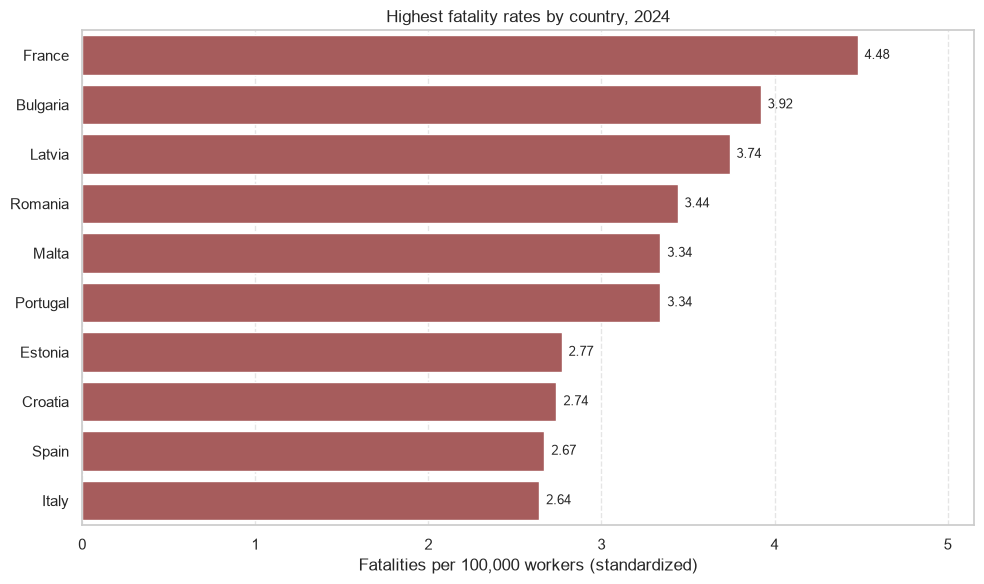

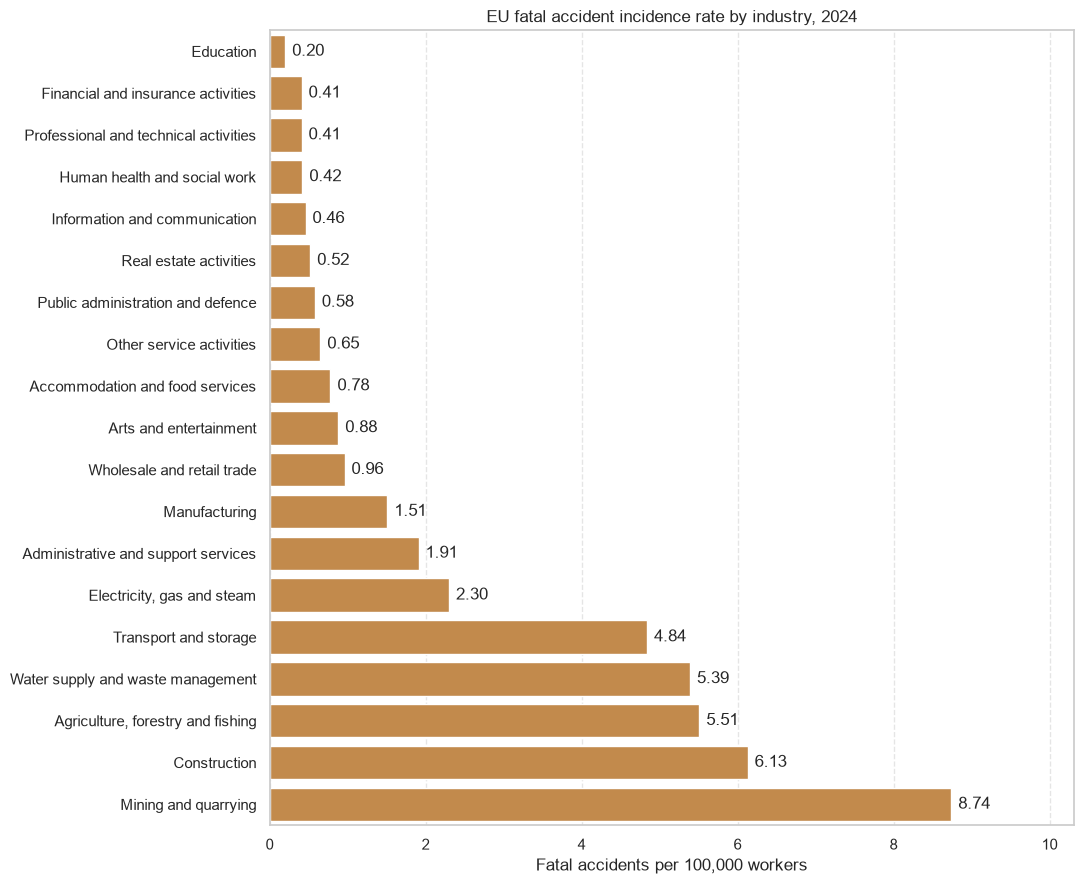

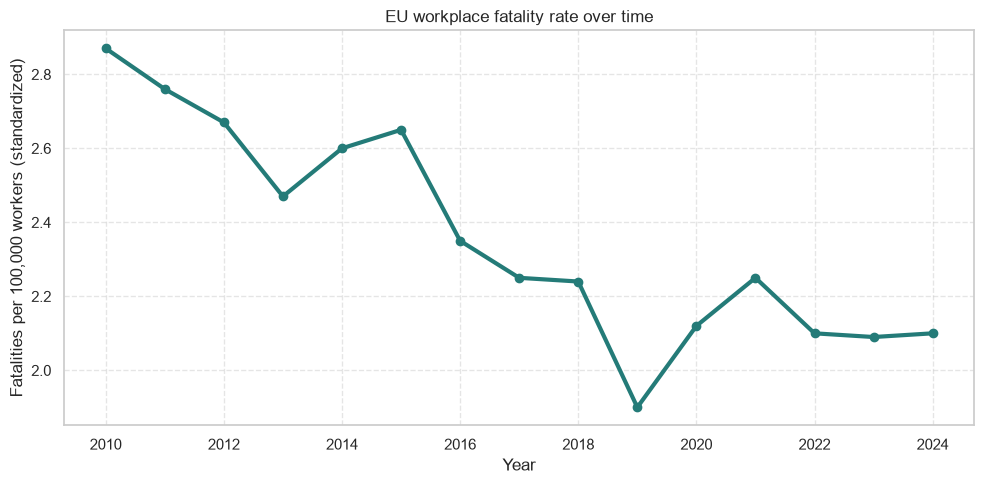

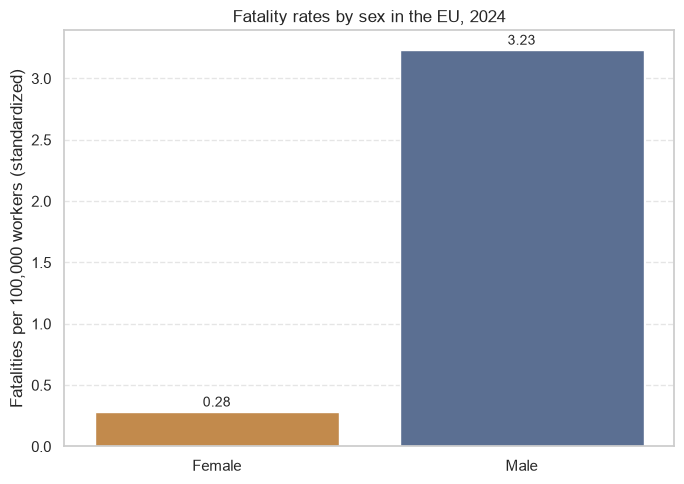

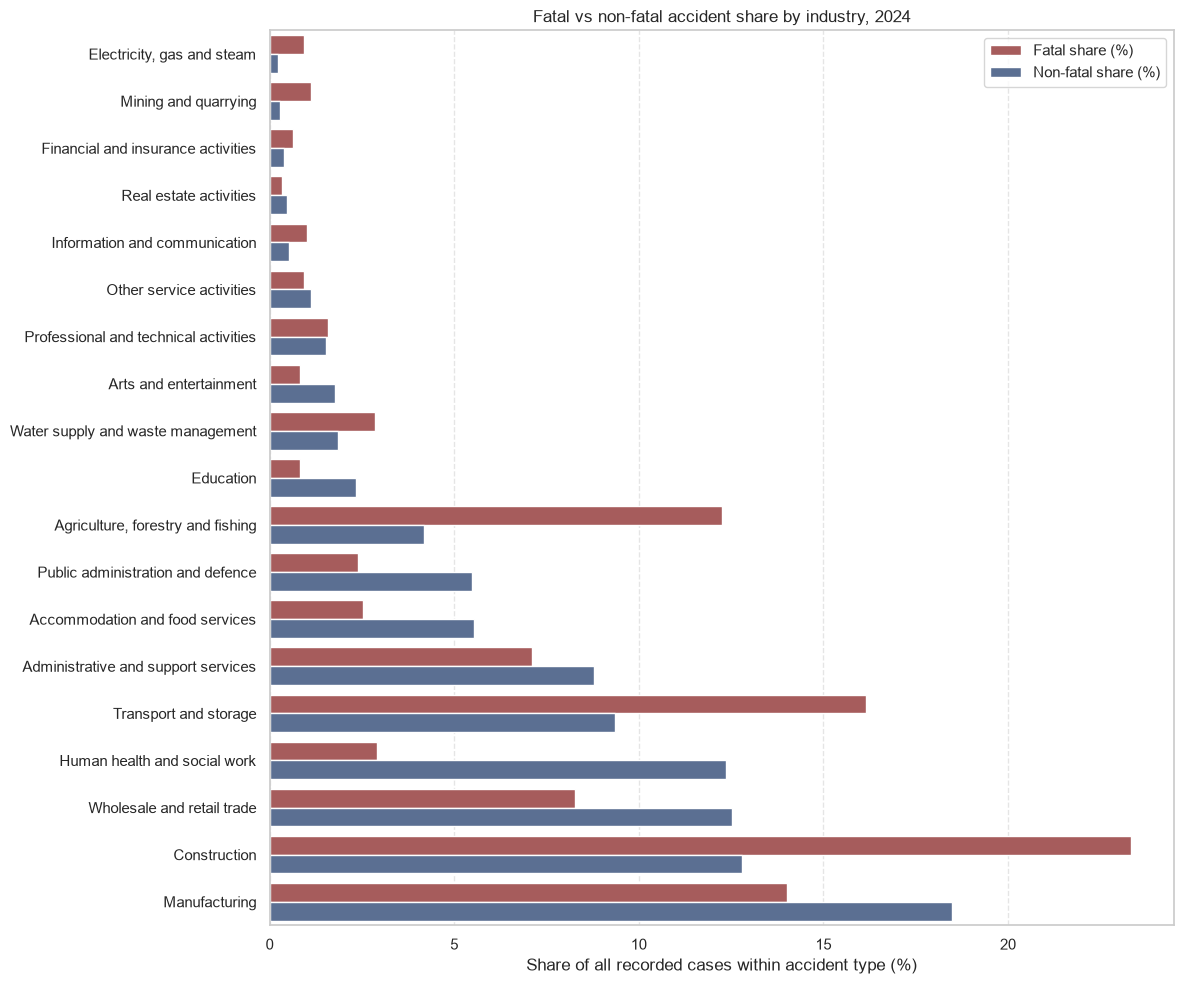

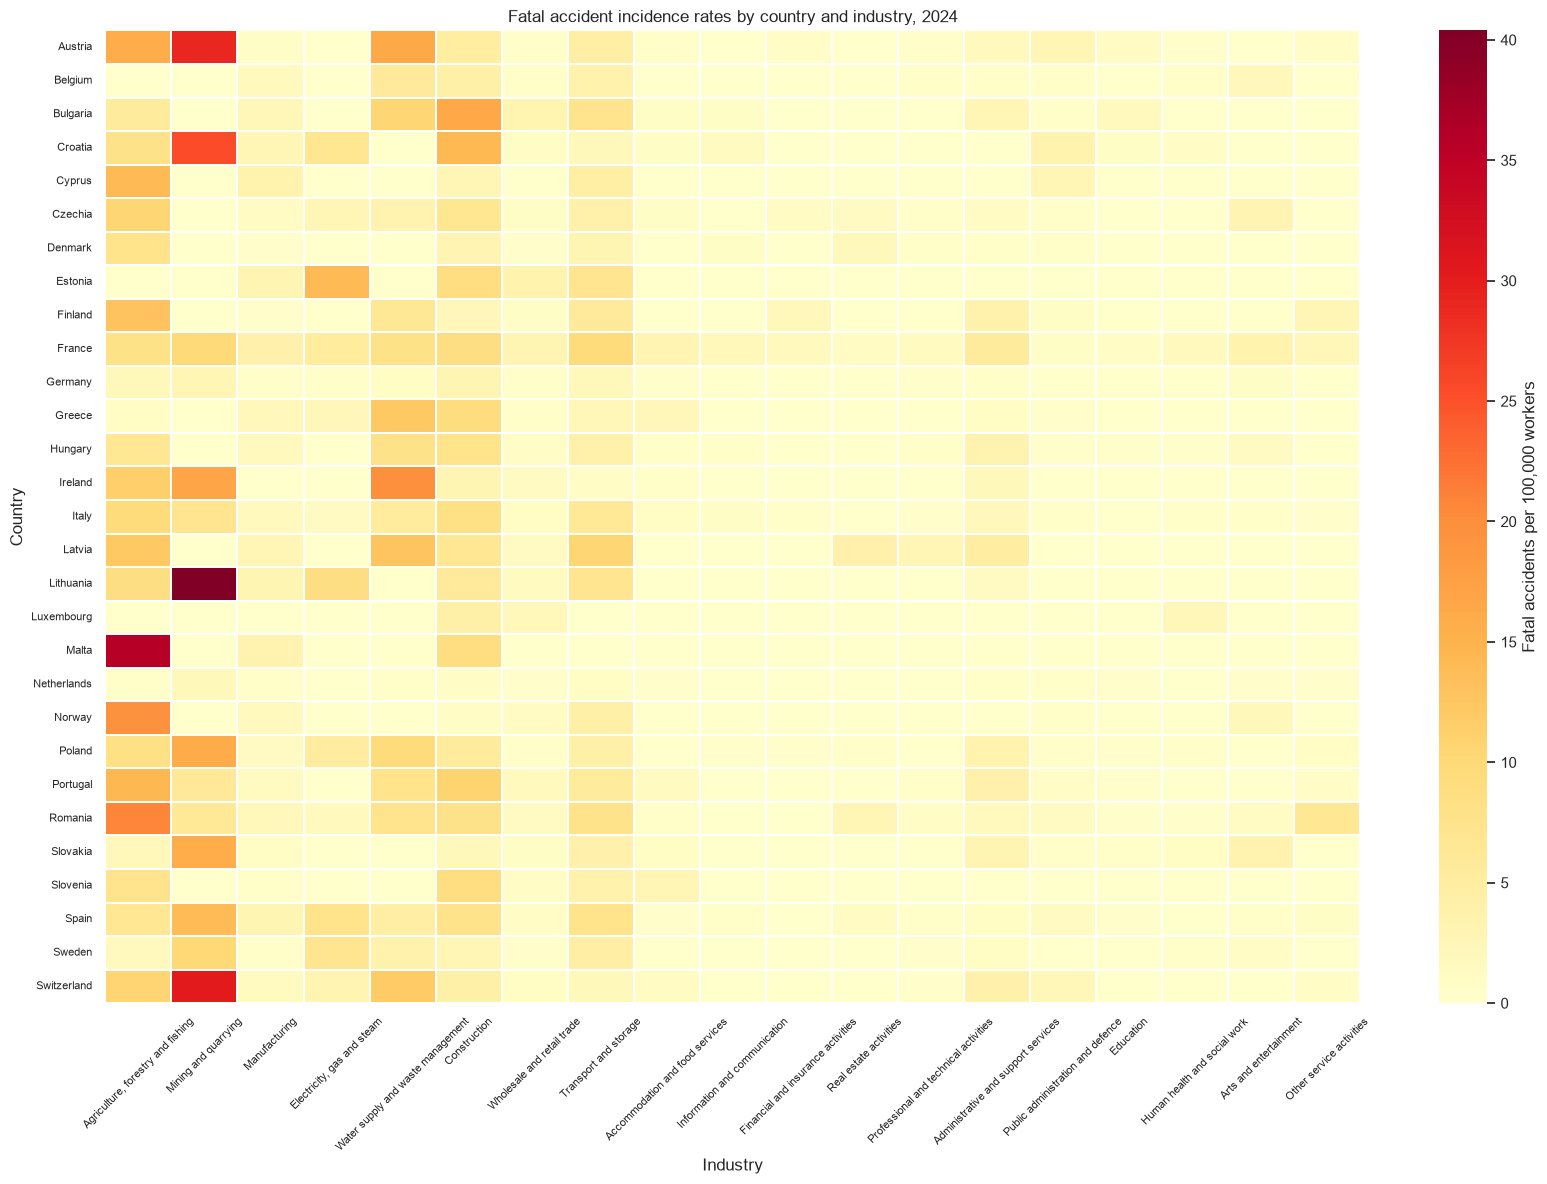

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Countries with the highest standardized fatality rates.
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=country_rates_table,
    x="Fatalities per 100,000 workers",
    y="Country",
    color="#b34f4f",
    ax=ax,
)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_width():.2f}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )
ax.set_xlim(0, country_rates_table["Fatalities per 100,000 workers"].max() * 1.15)
ax.set_title(f"Highest fatality rates by country, {analysis_year}")
ax.set_xlabel("Fatalities per 100,000 workers (standardized)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# 2. EU fatality incidence rate by broad industry.
fig, ax = plt.subplots(figsize=(11, 9))
sns.barplot(
    data=industry_rate_table.sort_values("Fatal accidents per 100,000 workers"),
    x="Fatal accidents per 100,000 workers",
    y="Industry",
    color="#d58b39",
    ax=ax,
)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_width():.2f}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=12,
    )
ax.set_xlim(0, industry_rate_table["Fatal accidents per 100,000 workers"].max() * 1.18)
ax.set_title(f"EU fatal accident incidence rate by industry, {analysis_year}")
ax.set_xlabel("Fatal accidents per 100,000 workers")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# 3. EU-wide trend in standardized fatality rates.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    trend_table["Year"],
    trend_table["Fatalities per 100,000 workers"],
    marker="o",
    color="#247b78",
    linewidth=3,
    markersize=6,
    )
ax.set_title("EU workplace fatality rate over time")
ax.set_xlabel("Year")
ax.set_ylabel("Fatalities per 100,000 workers (standardized)")
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# 4. Compare male and female standardized fatality rates.
sex_chart = pd.DataFrame({
    "Sex": ["Female", "Male"],
    "Fatalities per 100,000 workers": [
        sex_comparison_table.loc[0, "Female rate per 100,000 workers"],
        sex_comparison_table.loc[0, "Male rate per 100,000 workers"],
    ],
})
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(
    data=sex_chart,
    x="Sex",
    y="Fatalities per 100,000 workers",
    hue="Sex",
    palette={"Female": "#d58b39", "Male": "#526c9b"},
    legend=False,
    ax=ax,
)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )
ax.set_title(f"Fatality rates by sex in the EU, {analysis_year}")
ax.set_ylabel("Fatalities per 100,000 workers (standardized)")
ax.set_xlabel("")
ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# 5. Compare the industry distribution of fatal and non-fatal accidents.
comparison_chart = fatal_nonfatal_table.sort_values("Non-fatal share (%)").melt(
    id_vars="Industry",
    value_vars=["Fatal share (%)", "Non-fatal share (%)"],
    var_name="Accident type",
    value_name="Share of cases (%)",
)
fig, ax = plt.subplots(figsize=(12, 10))
sns.barplot(
    data=comparison_chart,
    x="Share of cases (%)",
    y="Industry",
    hue="Accident type",
    palette={"Fatal share (%)": "#b34f4f", "Non-fatal share (%)": "#526c9b"},
    ax=ax,
)
ax.set_title(f"Fatal vs non-fatal accident share by industry, {analysis_year}")
ax.set_xlabel("Share of all recorded cases within accident type (%)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.legend(title="")
fig.tight_layout()
plt.show()

# 6. Heatmap of fatal accident incidence rates by country and broad industry.
fig, ax = plt.subplots(figsize=(17, 12))
sns.heatmap(
    heatmap_matrix.sort_index(),
    cmap="YlOrRd",
    linewidths=0.25,
    linecolor="white",
    mask=heatmap_matrix.sort_index().isna(),
    cbar_kws={"label": "Fatal accidents per 100,000 workers"},
    ax=ax,
)
ax.set_title(f"Fatal accident incidence rates by country and industry, {analysis_year}")
ax.set_xlabel("Industry")
ax.set_ylabel("Country")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

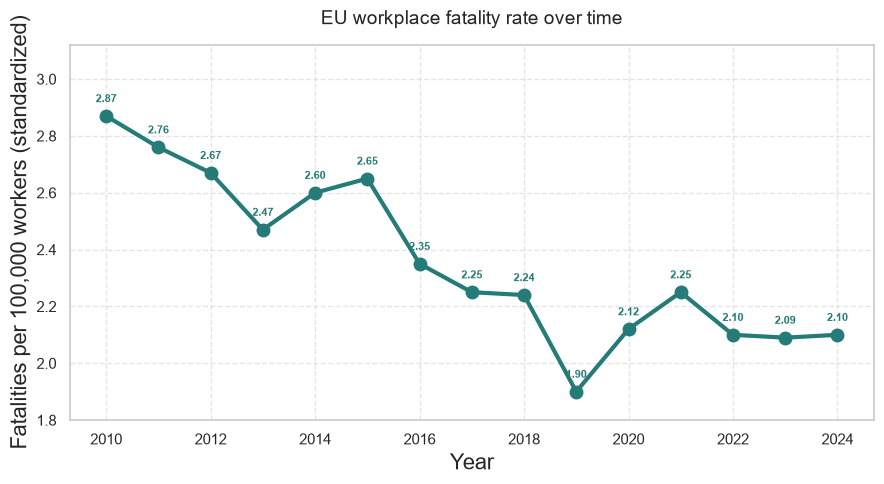

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 3. EU-wide trend in standardized fatality rates.
fig, ax = plt.subplots(figsize=(9, 5))  # Slightly wider figure

years = trend_table["Year"]
rates = trend_table["Fatalities per 100,000 workers"]

# Plot line with larger, wider markers
ax.plot(
    years,
    rates,
    marker="o",
    color="#247b78",
    linewidth=3,
    markersize=9,  # Increased dot size
)

# Add text labels above each data point
for x, y in zip(years, rates):
  ax.annotate(
      f"{y:.2f}",
      (x, y),
      textcoords="offset points",
      xytext=(0, 10),  # Distance in points from the dot
      ha="center",
      fontsize=9,
      fontweight="bold",
      color="#247b78",
  )

ax.set_title("EU workplace fatality rate over time", fontsize=14, pad=15)
ax.set_xlabel("Year", fontsize=16)
ax.set_ylabel("Fatalities per 100,000 workers (standardized)", fontsize=16)
ax.grid(True, linestyle="--", alpha=0.5)

# Add extra headroom on the y-axis so top labels are never cut off
ax.set_ylim(rates.min() - 0.1, rates.max() + 0.25)

fig.tight_layout()
plt.show()

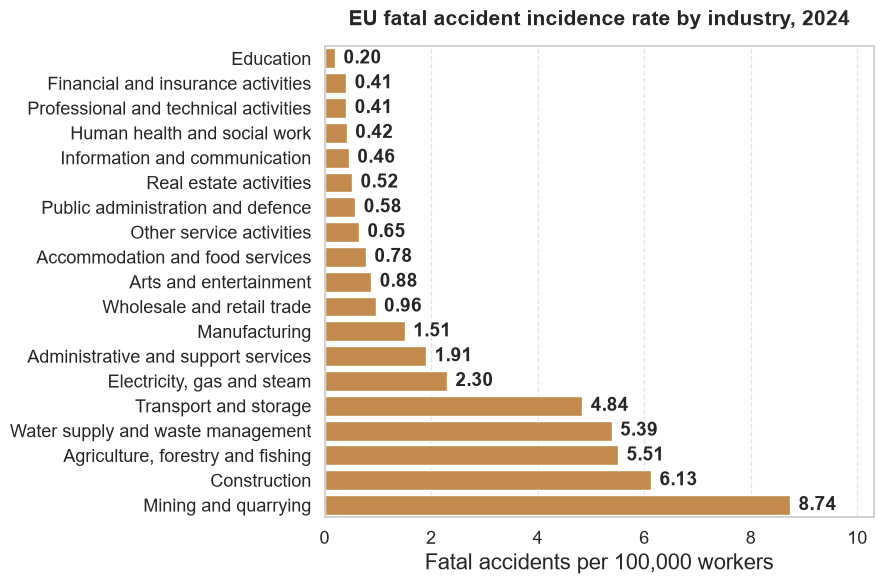

In [24]:
# 2. EU fatality incidence rate by broad industry.
fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=industry_rate_table.sort_values("Fatal accidents per 100,000 workers"),
    x="Fatal accidents per 100,000 workers",
    y="Industry",
    color="#d58b39",
    ax=ax,
)

# Increased fontsize for the numbers at the end of the bars
for bar in ax.patches:
  ax.annotate(
      f"{bar.get_width():.2f}",
      (bar.get_width(), bar.get_y() + bar.get_height() / 2),
      xytext=(6, 0),
      textcoords="offset points",
      va="center",
      fontsize=14,  # Increased from 12 to 14
      fontweight="bold",  # Optional: makes them bolder and easier to spot
  )

ax.set_xlim(0, industry_rate_table["Fatal accidents per 100,000 workers"].max() * 1.18)

# Increased font sizes for titles and labels
ax.set_title(
    f"EU fatal accident incidence rate by industry, {analysis_year}",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Fatal accidents per 100,000 workers", fontsize=16)
ax.set_ylabel("")

# Optional: Make the industry names (y-axis) and numbers (x-axis) larger
ax.tick_params(axis="y", labelsize=13)
ax.tick_params(axis="x", labelsize=13)

ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

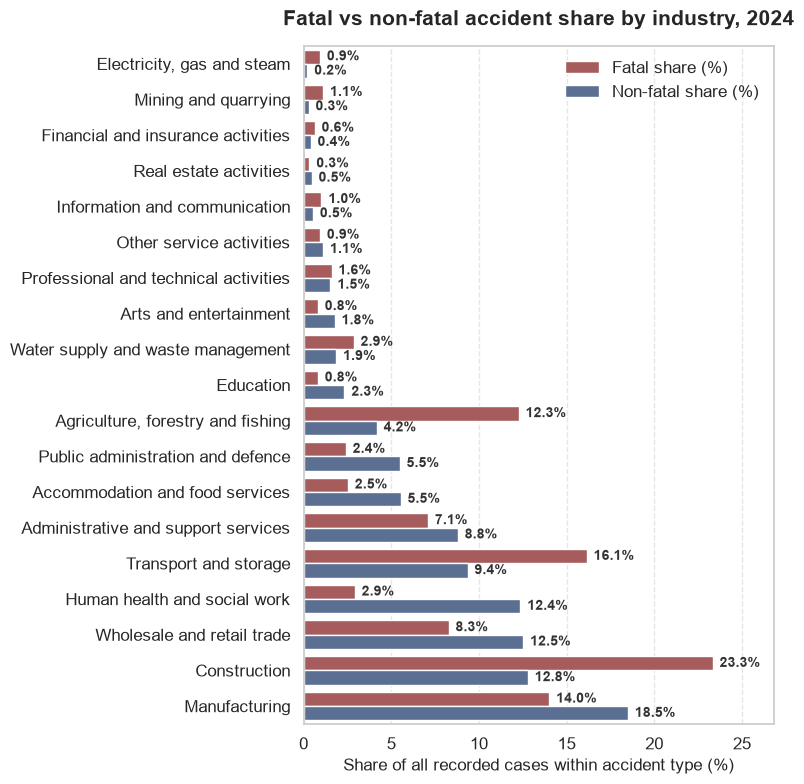

In [ ]:
# 5. Compare the industry distribution of fatal and non-fatal accidents.
comparison_chart = fatal_nonfatal_table.sort_values(
    "Non-fatal share (%)"
).melt(
    id_vars="Industry",
    value_vars=["Fatal share (%)", "Non-fatal share (%)"],
    var_name="Accident type",
    value_name="Share of cases (%)",
)

fig, ax = plt.subplots(figsize=(8, 8))

sns.barplot(
    data=comparison_chart,
    x="Share of cases (%)",
    y="Industry",
    hue="Accident type",
    palette={"Fatal share (%)": "#b34f4f", "Non-fatal share (%)": "#526c9b"},
    ax=ax,
)

# Loop through containers to add numeric labels to each bar
for container in ax.containers:
  ax.bar_label(
      container,
      fmt="%.1f%%",
      padding=5,  # Space between bar end and text
      fontsize=10,  # Font size for the labels
      fontweight="bold",
      color="#333333",
  )

# Extend x-axis limit so labels on the longest bars fit nicely
max_val = comparison_chart["Share of cases (%)"].max()
ax.set_xlim(0, max_val * 1.15)

# Styling and larger font sizes
ax.set_title(
    f"Fatal vs non-fatal accident share by industry, {analysis_year}",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Share of all recorded cases within accident type (%)", fontsize=12
)
ax.set_ylabel("")

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=12)

ax.grid(axis="x", linestyle="--", alpha=0.5)

# Clean legend styling
ax.legend(title="", fontsize=12, frameon=False)

fig.tight_layout()
plt.show()

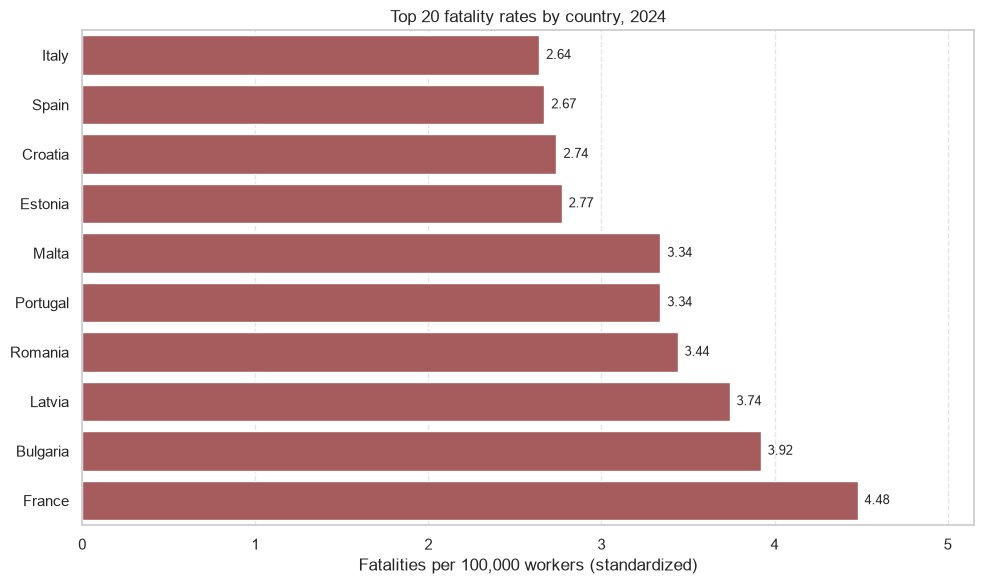

In [39]:
rate_column = "Fatalities per 100,000 workers"
plot_data = country_rates_table.sort_values(
    rate_column, ascending=False
)

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_data) * 0.35)))
sns.barplot(
    data=plot_data,
    x=rate_column,
    y="Country",
    order=plot_data.sort_values(rate_column)["Country"],
    color="#b34f4f",
    ax=ax,
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_width():.2f}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

ax.set_xlim(0, plot_data[rate_column].max() * 1.15)
ax.set_title(f"Top 20 fatality rates by country, {analysis_year}")
ax.set_xlabel("Fatalities per 100,000 workers (standardized)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

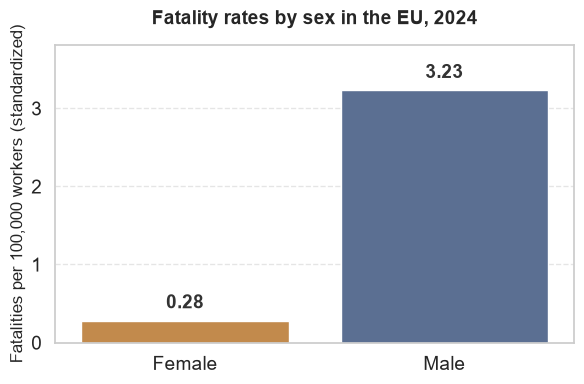

In [42]:
# 4. Compare male and female standardized fatality rates.
sex_chart = pd.DataFrame({
    "Sex": ["Female", "Male"],
    "Fatalities per 100,000 workers": [
        sex_comparison_table.loc[0, "Female rate per 100,000 workers"],
        sex_comparison_table.loc[0, "Male rate per 100,000 workers"],
    ],
})

fig, ax = plt.subplots(figsize=(6, 4))

sns.barplot(
    data=sex_chart,
    x="Sex",
    y="Fatalities per 100,000 workers",
    hue="Sex",
    palette={"Female": "#d58b39", "Male": "#526c9b"},
    legend=False,
    ax=ax,
)

# Larger, bold font size for the numbers on top of the bars
for bar in ax.patches:
  ax.annotate(
      f"{bar.get_height():.2f}",
      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
      xytext=(0, 6),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=14,  # Increased from 10 to 12
      fontweight="bold",
      color="#333333",
  )

# Add extra headroom at the top so the male bar label has plenty of room
ax.set_ylim(0, sex_chart["Fatalities per 100,000 workers"].max() * 1.18)

# Scaled up title and axes font sizes for professional consistency
ax.set_title(
    f"Fatality rates by sex in the EU, {analysis_year}",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_ylabel("Fatalities per 100,000 workers (standardized)", fontsize=12)
ax.set_xlabel("")

ax.tick_params(axis="y", labelsize=14)
ax.tick_params(axis="x", labelsize=14)

ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

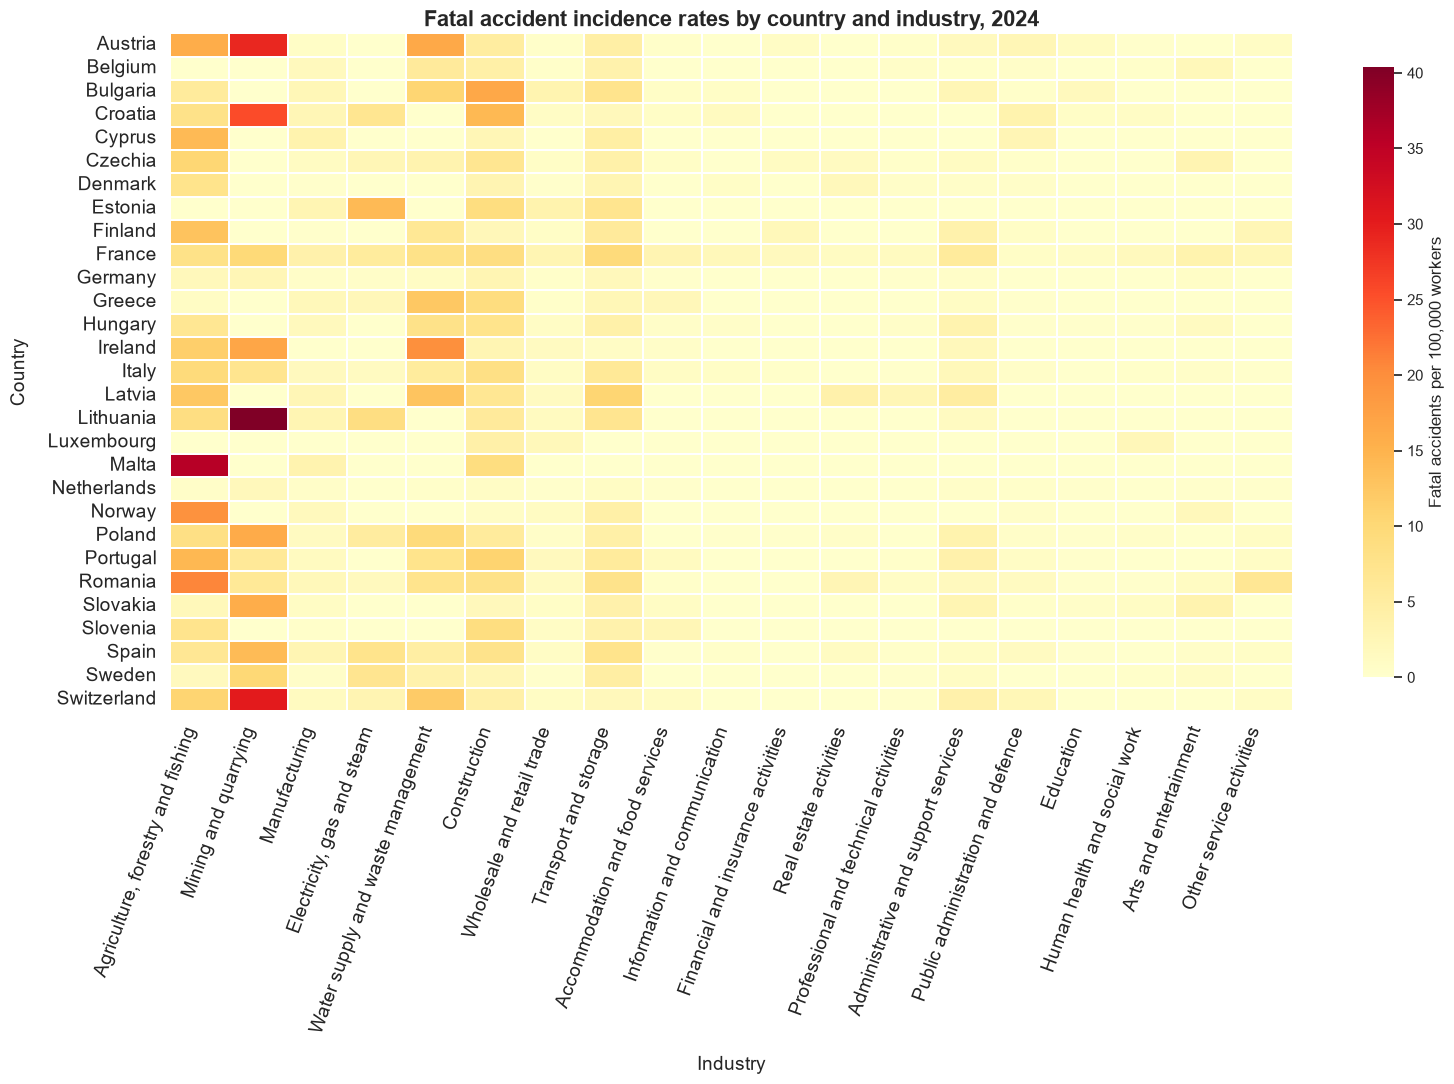

In [54]:
# 6. Heatmap of fatal accident incidence rates by country and broad industry.
fig, ax = plt.subplots(figsize=(16, 11))

# Sort index for consistent ordering
hm_data = heatmap_matrix.sort_index()

sns.heatmap(
    hm_data,
    cmap="YlOrRd",
    linewidths=0.3,  # Slightly clearer cell separation
    linecolor="white",
    mask=hm_data.isna(),
    cbar_kws={
        "label": "Fatal accidents per 100,000 workers",
        "shrink": 0.9,
    },  # Matches height better
    ax=ax,
)

# Clearer, larger titles and labels
ax.set_title(
    f"Fatal accident incidence rates by country and industry, {analysis_year}",
    fontsize=16,
    fontweight="bold",
    pad=5,
)
ax.set_xlabel("Industry", fontsize=14, labelpad=14)
ax.set_ylabel("Country", fontsize=14, labelpad=14)

# Larger, highly readable tick labels with proper alignment
ax.tick_params(axis="x", rotation=70, labelsize=14)
ax.set_xticklabels(
    ax.get_xticklabels(), ha="right"
)  # Aligns rotated labels cleanly
ax.tick_params(axis="y", labelsize=14, rotation=0)

fig.tight_layout()
plt.show()